# CelebA Simulation Results

DR-CPME + Riesz flow (AdamW) on frozen SD-VAE latents, DecFM confounding design
at 256 px. Sweep: $n_{\mathrm{obs}} \in \{1024 \dots 20000\}$, 3 DGP seeds, 3
repeats, both arms. The 64 px columns re-score the same decoded images at the
resolution of the DecFM paper's Figure 4.

The headline metric is the DecFM paper's: **SW2 in flat pixel space between the
decoded flow output and held-out counterfactual samples** (1000 projections),
arms averaged within each run, repeats within each seed, mean $\pm$ sd across
seeds. "No flow" scores the observed arm the same way; "floor" is
counterfactual-vs-counterfactual.

In [1]:
import glob

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.width", 140)


def load_results(pattern):
    "Concatenate every parsable task CSV (skips files a running task has not filled)."
    frames = []
    for f in sorted(glob.glob(pattern)):
        try:
            frames.append(pd.read_csv(f))
        except Exception:
            pass
    frame = pd.concat(frames, ignore_index=True)
    print(f"{len(frames)} files -> {len(frame)} rows")
    return frame


def headline(frame, value, by):
    '''Mean +/- sd of `value` vs the swept parameter(s) `by`.

    Aggregation order (the DecFM paper convention): arms averaged within each
    run first, then repeats within each data seed, then mean +/- sd across seeds.
    '''
    per_run = frame.groupby([*by, "data_seed", "repeat"])[value].mean()
    per_seed = per_run.groupby([*by, "data_seed"]).mean()
    return per_seed.groupby(list(by)).agg(["mean", "std"])


def sweep_table(frame, columns, by):
    "One table: each (column -> label) as `mean +- sd` against the swept parameter."
    out = {}
    for column, label in columns.items():
        stats = headline(frame, column, by)
        out[label] = (stats["mean"].map("{:.4f}".format) + " ± "
                      + stats["std"].map("{:.4f}".format))
    return pd.DataFrame(out)


def sweep_plot(ax, frame, columns, by, xlabel, logx=True):
    "Flow curve with a seed band; baselines as plain lines."
    styles = {"flow": ("tab:blue", "-"), "no flow": ("tab:red", ":"),
              "floor": ("tab:green", "--")}
    for column, label in columns.items():
        key = ("flow" if "flow" in label and "no" not in label
               else "no flow" if "no" in label else "floor")
        color, ls = styles[key]
        stats = headline(frame, column, by)
        ax.plot(stats.index, stats["mean"], marker="o", ms=4, color=color,
                linestyle=ls, label=label)
        if key == "flow":
            ax.fill_between(stats.index, stats["mean"] - stats["std"],
                            stats["mean"] + stats["std"], color=color, alpha=0.15)
    if logx:
        ax.set_xscale("log")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("pixel SW2 to counterfactual samples")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.25)

results = load_results("../CelebA/dr_mmd_flow/results/celeba_riesz_*.csv")
COLUMNS = {"sw2_flow": "SW2 flow", "sw2_observed": "SW2 no flow",
           "sw2_floor": "SW2 floor"}
COLUMNS_64 = {"sw2_64_flow": "64px SW2 flow", "sw2_64_observed": "64px SW2 no flow",
              "sw2_64_floor": "64px SW2 floor"}

18 files -> 108 rows


## SW2 vs sample size (native 256 px, and at 64 px)

In [2]:
pd.concat([sweep_table(results, COLUMNS, ["n_obs"]),
           sweep_table(results, COLUMNS_64, ["n_obs"])], axis=1)

,SW2 flow,SW2 no flow,SW2 floor,64px SW2 flow,64px SW2 no flow,64px SW2 floor
n_obs,,,,,,
1024,0.0614 ± 0.0031,0.0700 ± 0.0078,0.0457 ± 0.0024,0.0592 ± 0.0025,0.0670 ± 0.0071,0.0443 ± 0.0020
2048,0.0485 ± 0.0070,0.0702 ± 0.0120,0.0415 ± 0.0029,0.0466 ± 0.0064,0.0659 ± 0.0108,0.0403 ± 0.0027
4096,0.0387 ± 0.0022,0.0587 ± 0.0035,0.0405 ± 0.0026,0.0375 ± 0.0017,0.0552 ± 0.0027,0.0396 ± 0.0026
8192,0.0415 ± 0.0050,0.0594 ± 0.0005,0.0403 ± 0.0014,0.0401 ± 0.0043,0.0564 ± 0.0004,0.0392 ± 0.0013
16384,0.0401 ± 0.0008,0.0550 ± 0.0048,0.0412 ± 0.0017,0.0389 ± 0.0008,0.0518 ± 0.0042,0.0397 ± 0.0018
20000,0.0395 ± 0.0029,0.0488 ± 0.0018,0.0400 ± 0.0024,0.0386 ± 0.0029,0.0467 ± 0.0020,0.0388 ± 0.0020


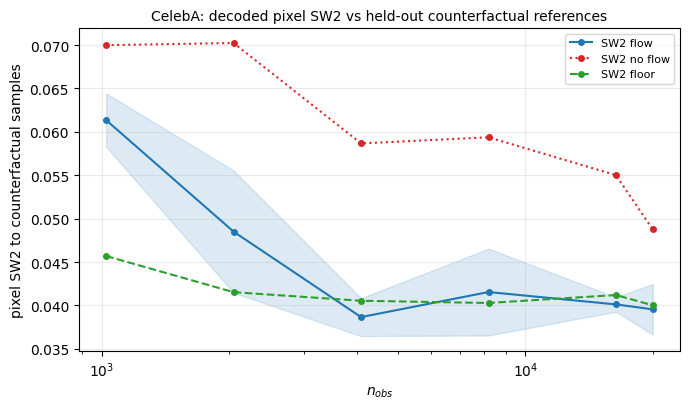

In [3]:
fig, ax = plt.subplots(figsize=(7, 4.2))
sweep_plot(ax, results, COLUMNS, ["n_obs"], "$n_{obs}$")
ax.set_title("CelebA: decoded pixel SW2 vs held-out counterfactual references",
             fontsize=10)
fig.tight_layout()
plt.show()

## Summary

- The flow reaches its floor at $n = 4096$ and tracks it flat to $n = 20000$
  (SW2 $0.0614 \to 0.0387 \to 0.0395$ against floors $\approx 0.040$).
- The male arm's deficit at small $n$ is data volume (particle cap + overlap),
  gone from $n = 4096$; the 64 px view tells the identical story.